## Image Search Series Part V: Pathology Tissue Slides Search with GigaPath (Prov-GigaPath)

In this tutorial, we show you how to build and optimize a 2D image search system for pathology tissue slide images using pathology foundation model **GigaPath embeddings**.

## Prerequisites

This notebook requires the following setup. If you haven't completed these steps, please refer to the Getting Started section in the main README, which includes:

1. Deploying required models
2. Installing the Healthcare AI Toolkit
3. Downloading sample data
4. Configuring your `.env` file

### Required for This Notebook

- **Model Endpoint(s)**: `GIGAPATH_MODEL_ENDPOINT` 
- **Additional Dependencies**: 
  ```bash
  conda install -c pytorch faiss-cpu
  ```

> **Note**: [FAISS](https://github.com/facebookresearch/faiss) provides efficient algorithms for searching large sets of vectors, making it perfect for building scalable image search systems like the one in this tutorial.

### Dataset
For this tutorial, we provide a sample set of pre-computed features from the [TCGA-GBMLGG](https://github.com/mahmoodlab/PathomicFusion/tree/master/data/TCGA_GBMLGG) dataset, which contains 2D pathology tissue slide images with corresponding tumor grade labels.

| Property | Value |
|----------|-------|
| **Total Subjects** | 170 |
| **Training Set** | ~80% |
| **Test Set** | ~20% |
| **Tumor Grades** | Grade 0, Grade 1, Grade 2 (3 classes) |
| **Embedding Dimension** | 1536 (GigaPath) |
| **Image Type** | H&E stained pathology slides |

###  2D Pathology Image Retrieval Overview

In this tutorial, we will guide you through the key steps of pathology image retrieval starting from analyzing the dataset distribution, generating embeddings from pathology foundation models, computing similarity between the query image and the cancer site image database, and finally performing evaluation with retrieval visualization. Below is a high-level outline of each step:

#### Steps in this Tutorial

1. **Set up and Data Preparation**
   - Authenticate with AzureML and load the online GigaPath client.

2. **Generate Image Embeddings With Pathology Foundation Models** 
    - Generate 1-D embeddings for each image using the online REST API endpoint.
    - **Note:** Pre-computed embeddings are available for convenience.

3. **Perform Retrieval with the Query Embeddings**
    - **Build FAISS Index**  
        - Create a FAISS index using the GigaPath embeddings.
    - **Evaluate and Display Search Results**  
        - Evaluate classification accuracy with respect to tumor grades and compute precision @1, @3, and @5.
        - Visualize query images alongside their retrieved neighbors.

4. **Optimize the Search**
   - **Train the Adapter and Generate New Embeddings**  
     - Train an adapter model to refine the embeddings using a tumor grading classification task.
   - **Generate Optimized FAISS Index and Evaluate Search Results**  
     - Build a FAISS index using the optimized embeddings and evaluate the search results.
     - Visualize query images and their neighbors with the improved embeddings.
     - **Bonus:** Indirectly retrieve and visualize the corresponding MRI from the recommended subjects

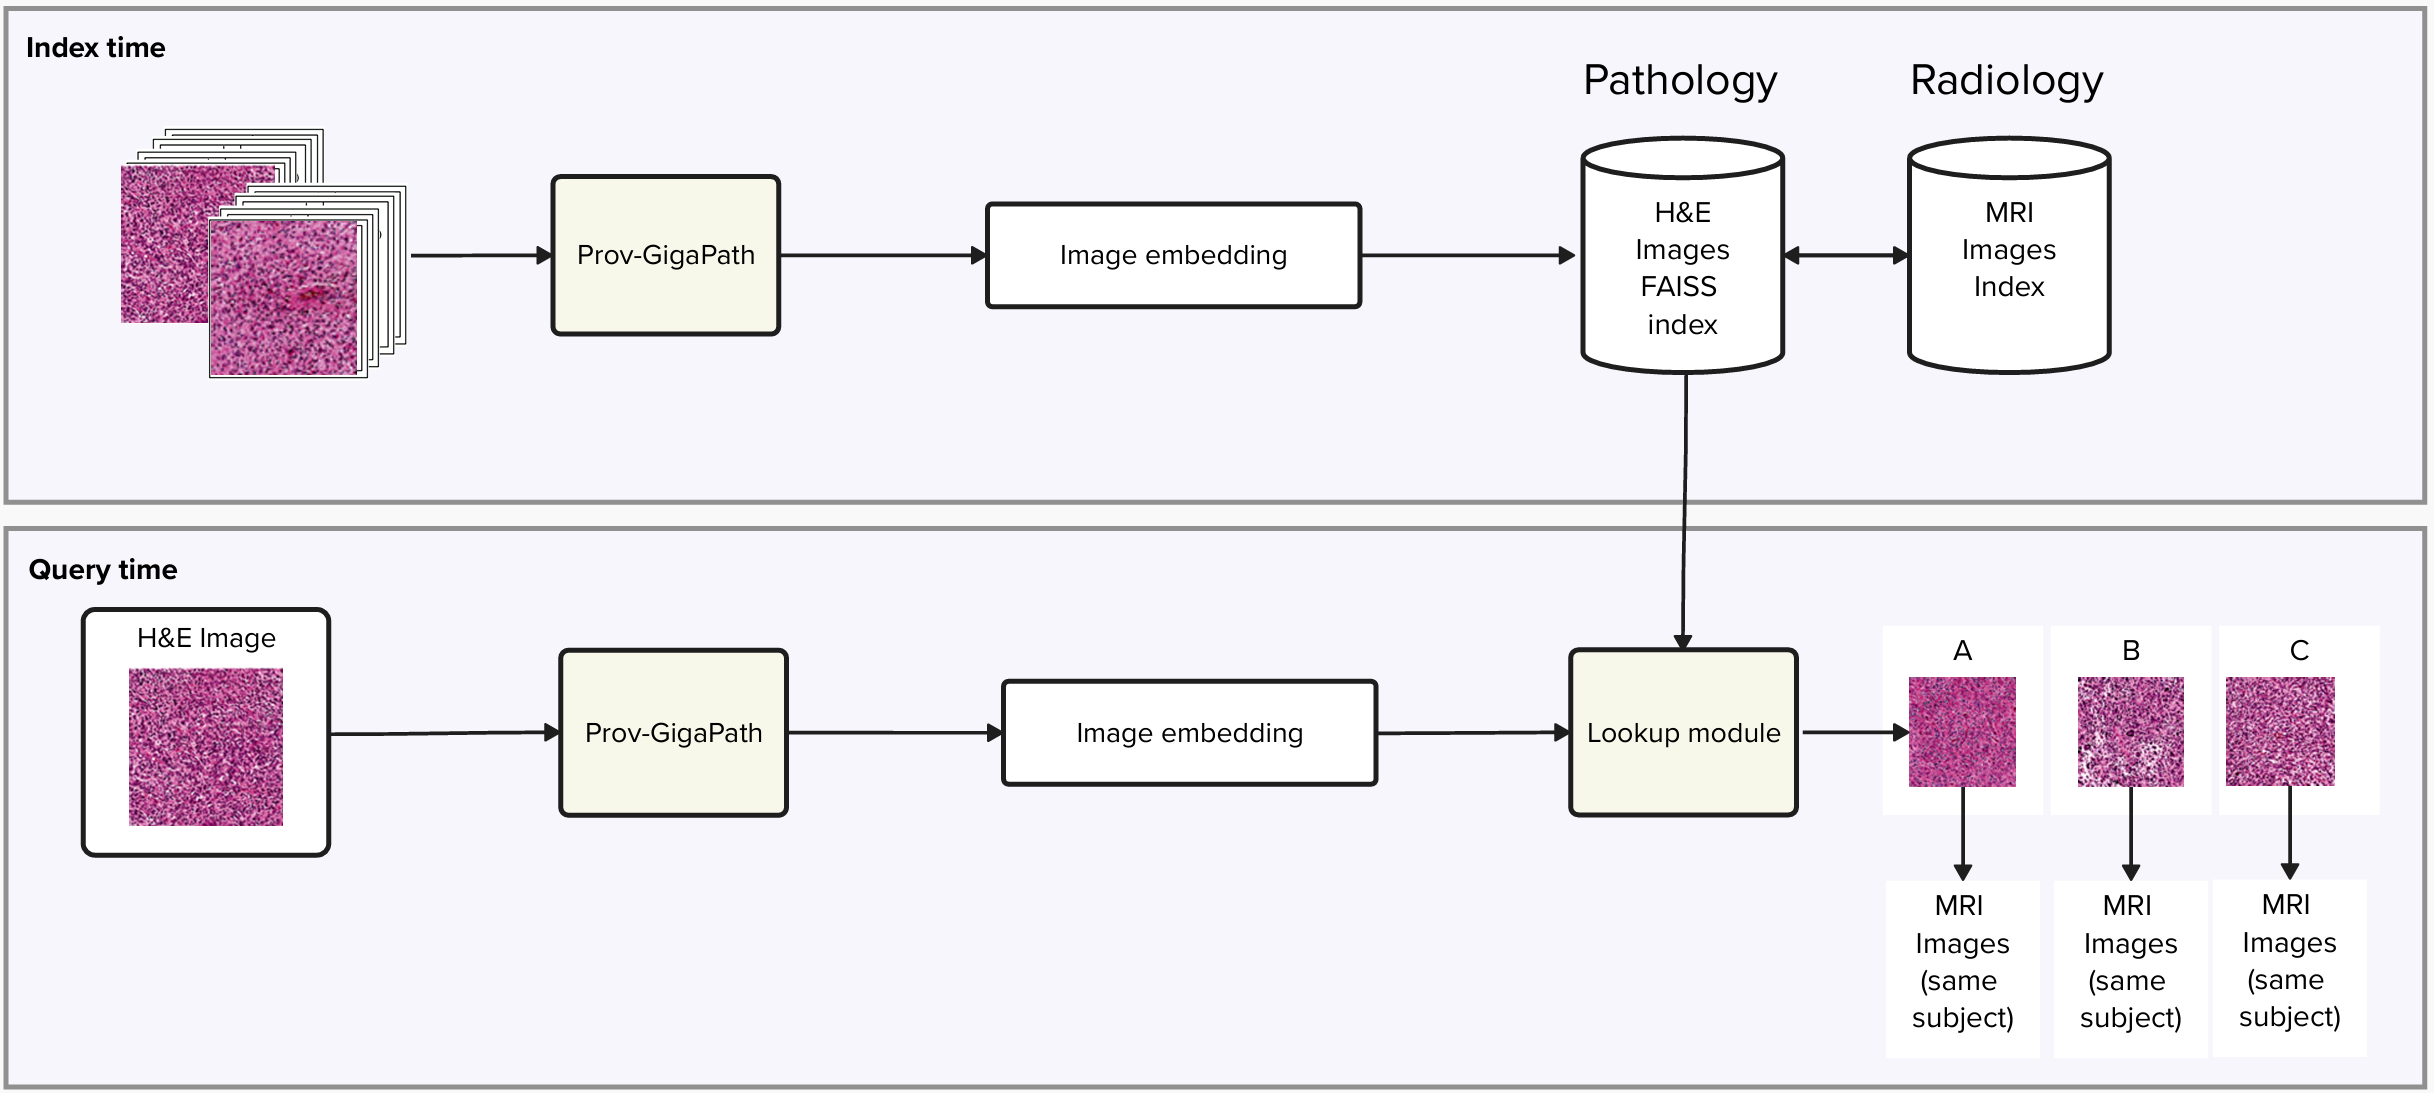

## What is Pathology Image Retrieval?

**Pathology image retrieval** is a specialized process of searching and retrieving relevant digital pathology images from large databases. This typically involves advanced computational techniques, from image processing and computer vision to machine learning algorithms, that analyze morphological patterns, structural features, or accompanying metadata. By efficiently retrieving images with similar visual or clinical characteristics, pathology image retrieval can streamline diagnostic workflows, facilitate research, and support educational applications.

### Why is this important?
1) Enhanced Diagnostic Accuracy: By retrieving highly relevant images for comparative analysis, pathologists can better identify patterns, leading to improved diagnostic outcomes.
2) Accelerated Clinical Workflows: Automated retrieval systems reduce time spent manually searching for examples or reference cases, allowing clinicians to focus on patient care.
3) Data-Driven Research: Researchers can quickly access large datasets of similar cases, enabling faster discovery of new insights or disease markers.

In this tutorial, we will provide step-by-step guidance starting from data acquisition and preprocessing, to extracting meaningful features from pathology images, and ultimately implementing methods to efficiently retrieve these images. Let's get started!

## **1. Set up and data preparation**

In [1]:
## Load Packages for the tutorial
import pandas as pd
import torch
import os
import numpy as np
import glob
import pickle
import umap
import matplotlib.pyplot as plt

from model_library.utils import training
from model_library.embedding import AdapterModel

from healthcareai_toolkit import settings
from healthcareai_toolkit.clients import GigaPathClient

Point to the data directory.

In [2]:
## Input Images and Text for Inference
data_root = settings.DATA_ROOT

if not os.path.exists(data_root):
    raise (
        Exception(
            f"Please download the files as described in this notebook into the data_root: {data_root}"
        )
    )

## Path for pathology tissue images
path_image_path = os.path.join(
    data_root, "advanced-pathology-image-search/sample_images/pathology"
)
## Path to labels and splits
path_csv_path = os.path.join(data_root, "advanced-radpath-demo")

Set up and authenticate the endpoint

In [3]:
from azure.ai.ml import MLClient
from azure.identity import DeviceCodeCredential

submit = False
if submit:
    # Authenticate with Azure ML
    credential = DeviceCodeCredential()
    ml_client = MLClient.from_config(credential)
    credential.authenticate()

## **2. Compute Embeddings**

Think of **GigaPath embeddings** as compact numerical representations of pathology image morphology. We first extract a feature map from GigaPath with shape **(1 × 1536 × 14 × 14)**, then apply adaptive average pooling to collapse the spatial dimensions. This produces a fixed-size embedding vector of shape **(1 × 1536)**.

For further reading:

- **Prov-GigaPath**: [A whole-slide foundation model for digital pathology from real-world data.](https://www.nature.com/articles/s41586-024-07441-w)  


> Note that while we walk you through generating the embeddings from source files, we also provide pre-computed embeddings in a .pkl file. 

### 2.1 Submit images to the GigaPath model endpoint or load pre-computed embeddings
This code retrieves a list of pathology image png files, submits them to the model endpoint, and saves the resulting image data to a pickle file. **If the data does not exist** in the `path_image_path` directory, it loads the embeddings from the pickle file for further processing. Consider using pre-computed embeddings if you do not want to wait until all files are processed, which may take a few minutes depending on your connection.

In [4]:
from search_utils import adaptive_pooling

# Load the train CSV file
train_csv_path = os.path.join(path_csv_path, "survival_adapter_train_split.csv")
test_csv_path = os.path.join(path_csv_path, "survival_adapter_test_split.csv")
# Load the train and test CSV files
train_df = pd.read_csv(train_csv_path)
test_df = pd.read_csv(test_csv_path)

# Set Formatted Label Category columns
train_df["Label Category"] = train_df["Grade"].astype(str)
test_df["Label Category"] = test_df["Grade"].astype(str)

train_df["Label Category"] = train_df["Label Category"].replace(
    {"0.0": "Grade 0", "1.0": "Grade 1", "2.0": "Grade 2"}
)
test_df["Label Category"] = test_df["Label Category"].replace(
    {"0.0": "Grade 0", "1.0": "Grade 1", "2.0": "Grade 2"}
)

train_df["Grade"] = train_df["Grade"].replace({0.0: "0", 1.0: "1", 2.0: "2"})
test_df["Grade"] = test_df["Grade"].replace({0.0: "0", 1.0: "1", 2.0: "2"})

merged_df = pd.concat([train_df, test_df])
image_subjects = merged_df["TCGA ID"].tolist()

# Define the path to save the pickle file
pkl_file_path = os.path.join(
    data_root, "advanced-pathology-image-search", "path_image_GigaPath_embeddings.pkl"
)

## If you want to get your own embeddings, you can follow the code below:
compute_embeddings = False
if compute_embeddings:
    # Get the list of image files with subject names
    image_files = [
        glob.glob(os.path.join(path_image_path, f"{tcga_id}*"))[0]
        for tcga_id in image_subjects
    ]

    # Connect to GigaPath Endpoint
    if submit:
        # GIGAPATH_MODEL_ENDPOINT should be specified in the .env file as described in the README
        endpoint = settings.GIGAPATH_MODEL_ENDPOINT
        gpath_client = GigaPathClient(endpoint, credential)
        submitter = gpath_client.create_submitter(n_jobs=2, return_as="list")
        image_index, image_results = submitter.submit(
            image_list=image_files, total=len(image_files)
        )

        # Apply adaptive pooling to each computed feature
        output_size = 1  # Example output size
        pooled_image_results = {
            image_files[v]: adaptive_pooling(
                image_results[v]["image_features"], output_size
            )
            for v in image_index
        }

        # Save the image_results to a pickle file
        with open(pkl_file_path, "wb") as f:
            pickle.dump(pooled_image_results, f)

# load image_results from the pickle file
with open(pkl_file_path, "rb") as f:
    image_results = pickle.load(f)

Here we create a DataFrame to ensure consistent ordering of the images and embeddings.

In [5]:
file_name_list = []
file_fullname_list = []
gpath_features_list = []

for k in image_results.keys():
    full_name = os.path.basename(k)

    # Extract case-level name (used for grouping / search)
    if "-01Z-" in full_name:
        name = full_name.split("-01Z-")[0]
    elif "-02Z-" in full_name:
        name = full_name.split("-02Z-")[0]
    else:
        name = full_name.split(".")[0]

    file_name_list.append(name)  # ← same as before
    file_fullname_list.append(full_name)  # ← NEW (actual file)
    gpath_features_list.append(np.array(image_results[k]))

# Final dataframe
gpath_features_df = pd.DataFrame(
    {
        "TCGA ID": file_name_list,  # for grouping / search
        "Name": file_fullname_list,  # for image loading
        "gigapath_features": gpath_features_list,  # renamed from 'features'
    }
)

### 2.2 Generate DataFrames to index embeddings and metadata
We create a DataFrame to store the embeddings and metadata. This DataFrame will be used to store the embeddings, metadata, and to build the FAISS index. The DataFrame’s index serves as the master index, which allows us to retrieve the corresponding metadata and embeddings efficiently.

In [6]:
# Merge the DataFrames with the features DataFrame on 'Name'
train_features_df = pd.merge(train_df, gpath_features_df, on="TCGA ID", how="inner")
test_features_df = pd.merge(test_df, gpath_features_df, on="TCGA ID", how="inner")

## **3. Perform Retrieval with Query Embeddings**

### 3.1 Build FAISS Index

FAISS supports efficient similarity search by indexing vectors. When using flat vectors, every vector is stored exactly, and an exact nearest neighbor search is performed by comparing all vectors using a distance metric, such as Euclidean distance.

This method relies on a flat index (IndexFlatL2) that guarantees high precision by exhaustively searching all vectors in memory. It works best with smaller datasets where search speed is not a primary concern; however, it may become slow when applied to larger datasets.

For larger datasets, you can consider alternative indexing techniques like HNSW (Hierarchical Navigable Small World) or IVFPQ (Inverted File with Product Quantization) that offer approximate searches, thereby enhancing speed while still balancing precision.


In [7]:
from search_utils import create_faiss_index

# Create the FAISS index for gigapath_features
gigapath_index = create_faiss_index(train_features_df, "gigapath_features")

### 3.2 Evaluate Search Performance
The search engine's effectiveness is quantified using **precision @1, @3,** and **@5**, which reflect the accuracy of the top retrieved images. Precision @1 measures how frequently the correct match appears as the very first result, while precision @3 and precision @5 assess the correctness among the top three and five matches, respectively. Additionally, **overall accuracy** is computed to give a complete picture of the model's performance across all categories.

Below, the code block processes a set of test images by performing lookups and retrieving top matches. The accuracy is then determined by checking if the retrieved images share the same condition labels as the query images.

In [8]:
from search_utils import evaluate_faiss_search

k_list = [1, 3, 5]

(
    gigapath_summary_df,
    gigapath_detail_df,
    gigapath_search_results_df,
) = evaluate_faiss_search(
    gigapath_index,
    test_features_df,
    train_features_df,
    k_list,
    query_column_feature_name="gigapath_features",
    eval_label="Grade",
)

display(gigapath_detail_df)
display(gigapath_summary_df)

,Label,Category,Precision @ k=1,Precision @ k=3,Precision @ k=5
0,0,Grade 0,0.500000,0.50000,0.550000
1,1,Grade 1,0.363636,0.30303,0.309091
2,2,Grade 2,0.875000,0.87500,0.862500


,k (Top-K),Overall Precision
0,1,0.579545
1,3,0.559343
2,5,0.573864


The baseline results offer an initial performance evaluation. Although the dataset is small, these results provide a preliminary understanding of the system effectiveness in retrieving relevant images. With access to a larger dataset and the ability to further optimize the embeddings, we can refine the model representation, leading to improved search accuracy and relevance.

### 3.3 Display images and retrieved neighbors

Here let's look at the top 5 matches for a few sample images from our test set. The first item in each row contains the query image, and the rest of items in the row contain the retrieved images with Rank indicating their proximity to the query image as determined by the embedding matching.

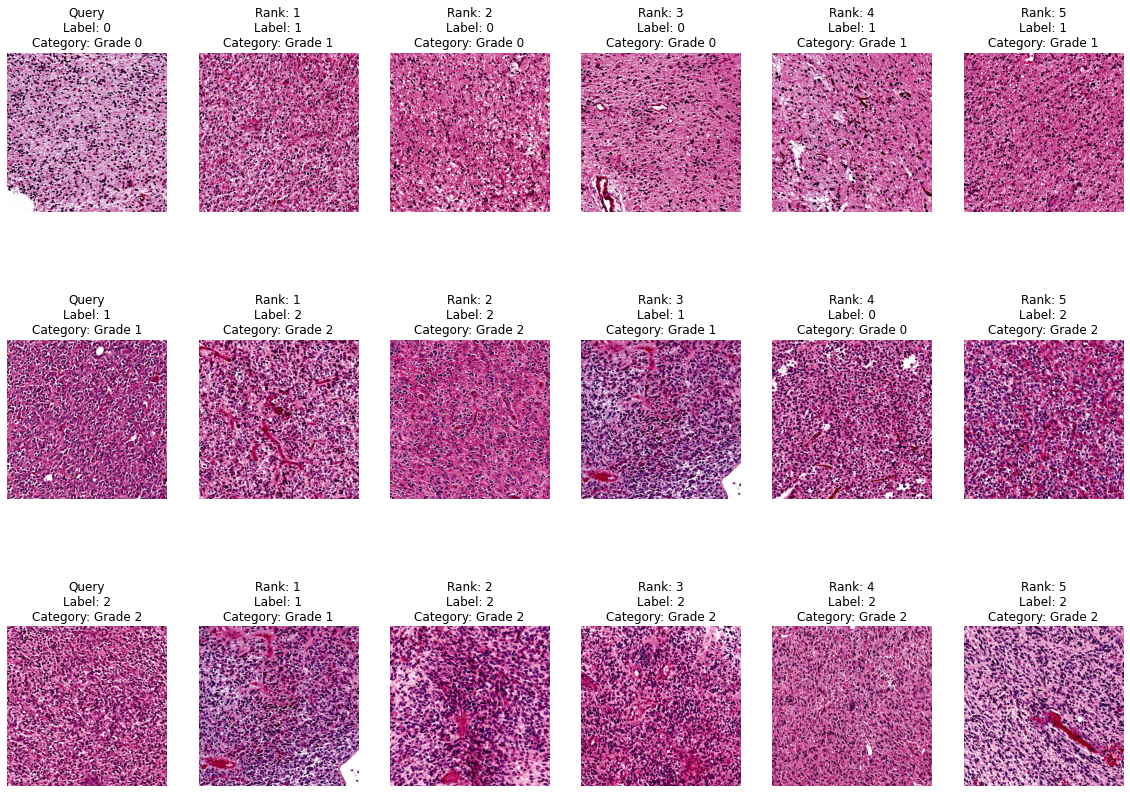

In [9]:
from search_utils import display_query_and_retrieved_images

# Select one sample per label for visualization
query_df = test_features_df.groupby("Grade").first().reset_index()
display_query_and_retrieved_images(
    query_df,
    gigapath_search_results_df,
    path_image_path,
    train_features_df,
    eval_label="Grade",
    cmap=None,
)

## **4. Optimize Image Search**
Now that we have seen the baseline performance, a natural question arises: how can we improve the system to optimize search for a particular criterion? The GigaPath model creates representations that may not be perfectly aligned with the specific search criteria relevant to your application. 

In this section, we optimize the performance by training an adapter model (as described in the [corresponding notebook](../../medimageinsight/adapter-training.ipynb) in this repository) and leveraging the tumor grading labels from our dataset to perform tumor grade classification. After this process, the embeddings generated by the GigaPath model paired with the adapter should be better aligned with tumor grading. 

### 4.1 Define data loaders to iterate over the GigaPath embeddings.


In [10]:
from search_utils import create_data_loader_from_df

# Create DataLoaders for train and validation sets
train_gpath_ds = create_data_loader_from_df(
    train_features_df, mode="train", category="Grade"
)
test_gpath_ds = create_data_loader_from_df(
    test_features_df, mode="val", category="Grade"
)

### 4.2 Train the adapter 

We define the **adapter model** for fine-tuning the embeddings. The model takes 1536 (GigaPath Feature Channel Size) input channels and outputs embeddings of size 254, with 3 output classes. The **CrossEntropyLoss** is used as the loss function for classification tasks, and the **AdamW** optimizer is applied with a learning rate of 0.0003. The model requires minimal computational resources and was trained for 30 epochs (~30 seconds) using a CPU VM [Standard_E4s_v3](https://learn.microsoft.com/en-us/azure/virtual-machines/ev3-esv3-series) (4 cores, 32 GB RAM, 64 GB disk).

Note that the adapter model itself is defined in our _healthcareai_toolkit_ utility package that is provided alongside this notebook. We further provide our pretrained model to reproduce the image visualization below. 

In [ ]:
## Setting the seed
import torch

torch.manual_seed(0)

## Define the model, transforms, optimizer and loss function
adapter_emb_size = 254

model = AdapterModel(in_channels=1536, hidden_dim=adapter_emb_size, num_class=3)
loss_function_ts = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0003)

## Define Output Directory
output_dir = os.path.join(
    data_root,
    "advanced-pathology-image-search",
    "adapter_model_output/path_retrieval_adapter_model_seed0",
)
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

## If you want to train your own model, you can set perform_training to True
max_epoch = 30
perform_training = False
if perform_training:
    selector = "accuracy"
    best_metric, _train_history, _val_history = training.trainer(
        train_gpath_ds,
        test_gpath_ds,
        model,
        loss_function_ts,
        optimizer,
        epochs=max_epoch,
        root_dir=output_dir,
        selector=selector,
    )
    print(f"Best {selector} of the Adaptor: {best_metric:.4f}")

### 4.3 Run Inference  

Now that we have updated our embedding strategy by integrating GigaPath embeddings with our newly trained adapter, we need to regenerate our FAISS index with the optimized embeddings. The code below runs inference using the trained adapter model on the existing GigaPath embeddings. This step is computationally efficient as it bypasses the need to reprocess the images through the GigaPath model API.

In [ ]:
from search_utils import perform_inference_and_return_features

train_gpath_ds.dataset.mode = "test"
test_gpath_ds.dataset.mode = "test"

## Load Trained Adaptor Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(
    torch.load(
        os.path.join(output_dir, "best_metric_model.pth"),
        weights_only=True,
        map_location=device,
    )
)
model.to(device)

## Perform Inference and Return Features
test_adapter_features_dict = perform_inference_and_return_features(model, test_gpath_ds)
train_adapter_features_dict = perform_inference_and_return_features(
    model, train_gpath_ds
)

### 4.4 Index Optimized Embeddings with Metadata  
To keep the data organized, we add the optimized embeddings to both the training and testing dataframes, along with the corresponding metadata.

In [13]:
train_adapter_features_list = []
train_adapter_name_list = []

for v in train_adapter_features_dict:
    train_adapter_features_list.append(
        np.reshape(np.array(v["Features"]), (adapter_emb_size,))
    )
    train_adapter_name_list.append(v["Name"])

gpath_adapter_features_inference_df = pd.DataFrame(
    {
        "Name": train_adapter_name_list,
        "gigapath_adapter_features": train_adapter_features_list,
    }
)

test_adapter_features_list = []
test_adapter_name_list = []

for v in test_adapter_features_dict:
    test_adapter_features_list.append(
        np.reshape(np.array(v["Features"]), (adapter_emb_size,))
    )
    test_adapter_name_list.append(v["Name"])

gpath_adapter_features_inference_test_df = pd.DataFrame(
    {
        "Name": test_adapter_name_list,
        "gigapath_adapter_features": test_adapter_features_list,
    }
)

train_features_df = pd.merge(
    train_features_df, gpath_adapter_features_inference_df, on="Name", how="inner"
)
test_features_df = pd.merge(
    test_features_df, gpath_adapter_features_inference_test_df, on="Name", how="inner"
)

### 4.5 Generate FAISS Index and Evaluate Search Results  
We create a new FAISS index using the optimized embeddings and then evaluate the search results to assess the improvements in retrieval accuracy.

In [14]:
# Create the FAISS index for gigapath_adapter_features
gpath_adapter_index = create_faiss_index(train_features_df, "gigapath_adapter_features")

(
    adapter_summary_df,
    adapter_detail_df,
    adapter_search_results_df,
) = evaluate_faiss_search(
    gpath_adapter_index,
    test_features_df,
    train_features_df,
    [1, 3, 5],
    query_column_feature_name="gigapath_adapter_features",
    eval_label="Grade",
)

display(adapter_detail_df)
display(adapter_summary_df)

,Label,Category,Precision @ k=1,Precision @ k=3,Precision @ k=5
0,0,Grade 0,0.625000,0.666667,0.625000
1,1,Grade 1,0.818182,0.848485,0.781818
2,2,Grade 2,0.875000,0.875000,0.900000


,k (Top-K),Overall Precision
0,1,0.772727
1,3,0.796717
2,5,0.768939


We display the optimized search results to compare the performance of the baseline and adapted models using GigaPath embeddings. In the optimized index, GigaPath embeddings have been fine-tuned with target labels, which should yield more clinically relevant image retrieval and improve the overall accuracy of the search. This side-by-side comparison allows us to assess the impact of the optimization process and demonstrates how tailoring GigaPath embeddings can enhance the system's effectiveness. Moreover, the results highlight potential areas for further improvements, such as refining the adapter model or expanding the dataset to achieve even better performance in real-world scenarios.

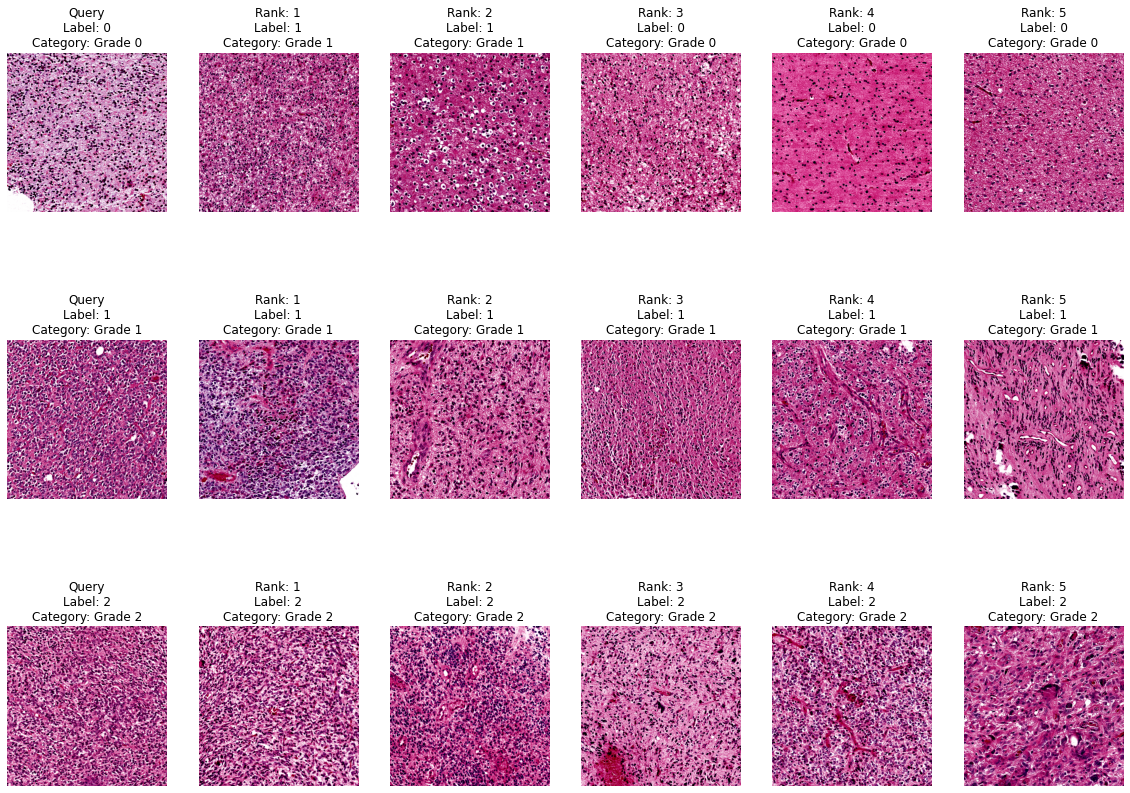

In [15]:
path_image_path = os.path.join(
    data_root, "advanced-pathology-image-search/sample_images/pathology"
)

display_query_and_retrieved_images(
    query_df,
    adapter_search_results_df,
    path_image_path,
    train_features_df,
    eval_label="Grade",
)

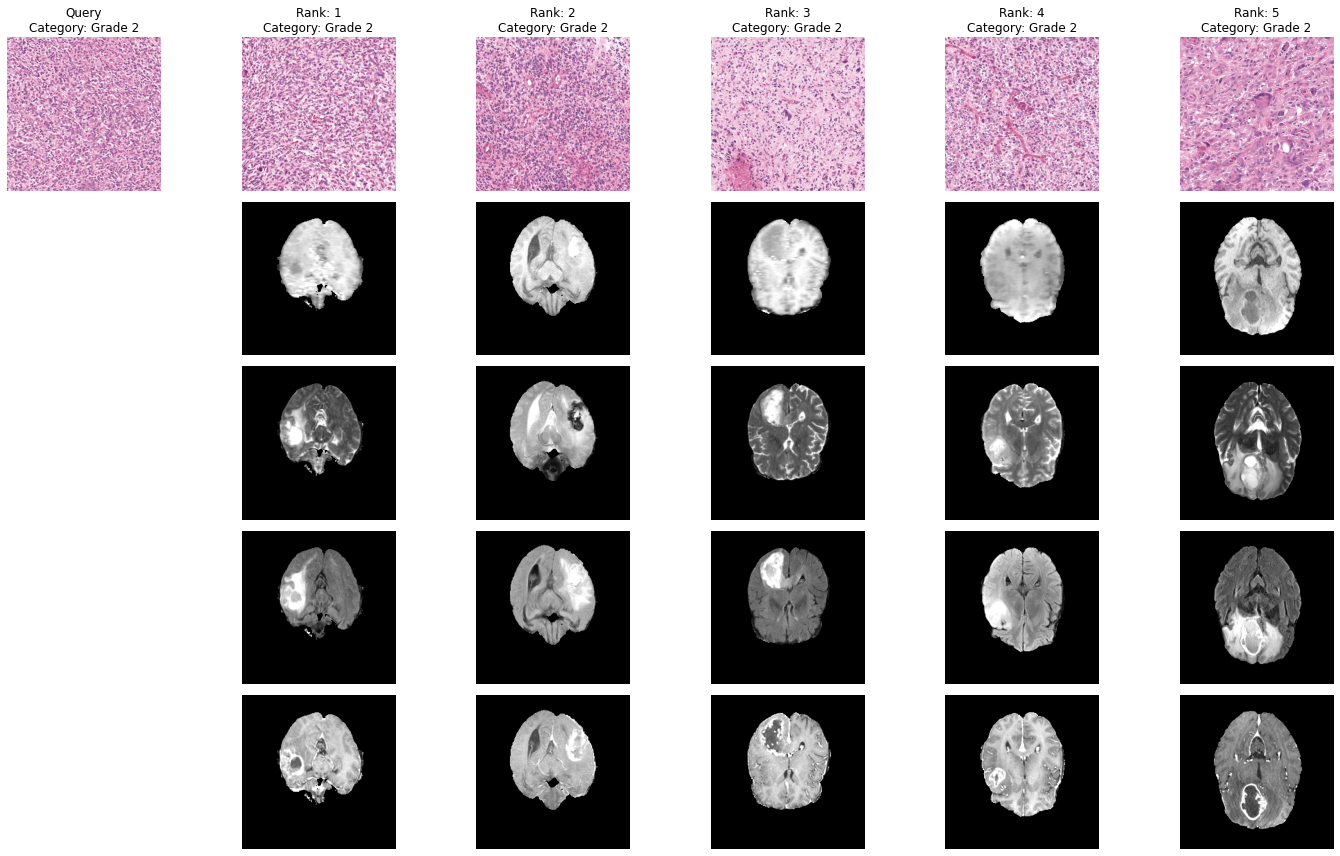

In [16]:
from search_utils import display_query_and_retrieved_images_radpath
import os, re


def rad_base_id_from_path_name(name: str) -> str:
    base = os.path.basename(name)

    if base.lower().endswith(".png"):
        base = base[:-4]

    base = re.sub(r"_[0-9]+$", "", base)  # drop _1, _2, ...
    base = base.split(".")[0]  # drop GUID part

    if "-01Z-" in base:
        base = base.split("-01Z-")[0]
    elif "-02Z-" in base:
        base = base.split("-02Z-")[0]

    return base


# Precompute normalized MRI base id ONCE
train_features_df = train_features_df.copy()
train_features_df["rad_id"] = train_features_df["Name"].apply(
    rad_base_id_from_path_name
)

rad_image_path = os.path.join(
    data_root, "advanced-pathology-image-search/sample_images/MRI"
)


display_query_and_retrieved_images_radpath(
    query_df,
    adapter_search_results_df,
    path_image_path,
    rad_image_path,
    train_features_df,
    eval_label="Grade",
)

### 4.6 Apply UMAP and Visualize Embeddings

We apply UMAP to the high-dimensional embeddings to reduce them to two dimensions. This allows us to:

- **Visualize the data**: Plot the images on a 2D plane to observe clusters and separations by tumor grade.
- **Compare embeddings**: Visualize how the baseline GigaPath embeddings and the adapter-optimized embeddings cluster the data differently.
- **Interpret clusters**: Identify if different tumor grades form distinct clusters, which supports the effectiveness of our adapter training.

In [17]:
# Extract the GigaPath embeddings for UMAP visualization
train_gigapath_features = np.vstack(train_features_df["gigapath_features"].values)
test_gigapath_features = np.vstack(test_features_df["gigapath_features"].values)

# Combine train and test for visualization
all_gigapath_features = np.vstack([train_gigapath_features, test_gigapath_features])
all_grades = pd.concat([train_features_df["Grade"], test_features_df["Grade"]]).values
all_splits = ["Train"] * len(train_features_df) + ["Test"] * len(test_features_df)

# Fit and transform using UMAP
reducer = umap.UMAP(random_state=42)
gigapath_embedding = reducer.fit_transform(all_gigapath_features)

In [18]:
# Extract the adapter-optimized embeddings for UMAP visualization
train_adapter_features = np.vstack(
    train_features_df["gigapath_adapter_features"].values
)
test_adapter_features = np.vstack(test_features_df["gigapath_adapter_features"].values)

# Combine train and test for visualization
all_adapter_features = np.vstack([train_adapter_features, test_adapter_features])

# Fit and transform using UMAP
reducer_adapter = umap.UMAP(random_state=42)
adapter_embedding = reducer_adapter.fit_transform(all_adapter_features)

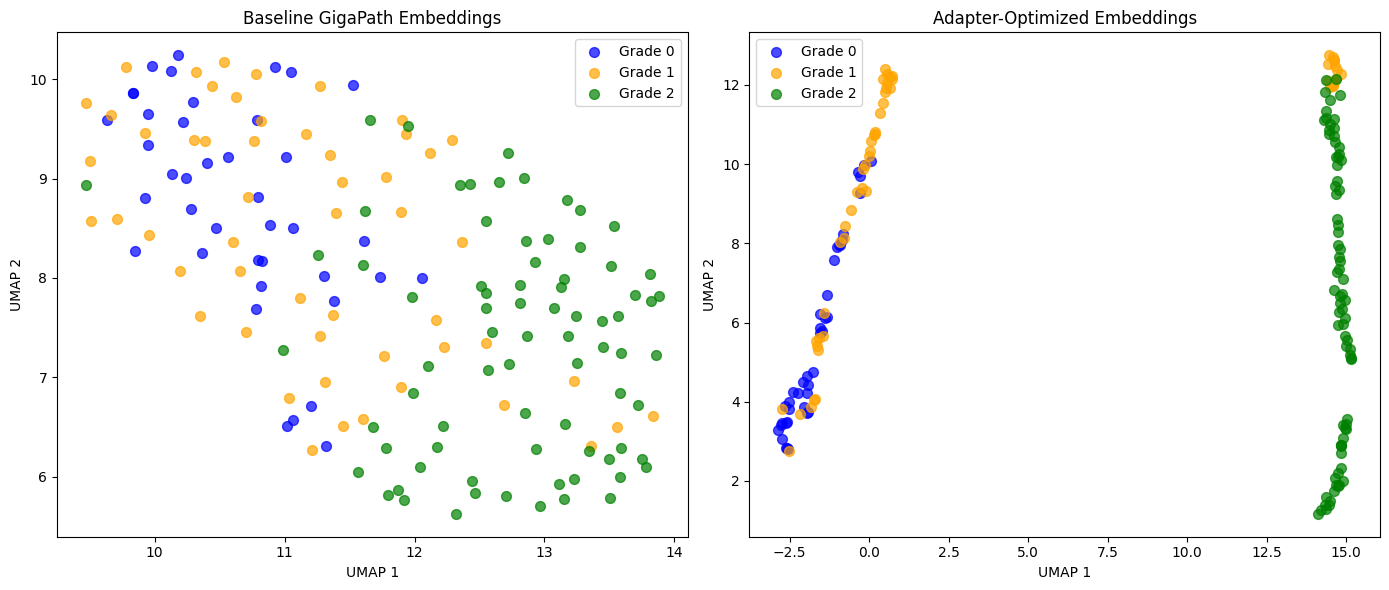

In [19]:
# Side-by-side comparison of baseline vs adapter embeddings
plt.figure(figsize=(14, 6))

grade_colors = {"0": "blue", "1": "orange", "2": "green"}

plt.subplot(1, 2, 1)
for grade in sorted(train_features_df["Grade"].unique()):
    mask = all_grades == grade
    plt.scatter(
        gigapath_embedding[mask, 0],
        gigapath_embedding[mask, 1],
        c=grade_colors[grade],
        label=f"Grade {grade}",
        alpha=0.7,
        s=50,
    )
plt.legend()
plt.title("Baseline GigaPath Embeddings")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.subplot(1, 2, 2)
for grade in sorted(train_features_df["Grade"].unique()):
    mask = all_grades == grade
    plt.scatter(
        adapter_embedding[mask, 0],
        adapter_embedding[mask, 1],
        c=grade_colors[grade],
        label=f"Grade {grade}",
        alpha=0.7,
        s=50,
    )
plt.legend()
plt.title("Adapter-Optimized Embeddings")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.tight_layout()
plt.show()

## Key Takeaways

This tutorial demonstrated how to build and optimize a 2D image search system using GigaPath embeddings and FAISS. By fine-tuning the embeddings with an adapter model, we achieved significantly improved search accuracy and more relevant image retrieval.

The visualization above illustrates how the optimized GigaPath embeddings enhance the retrieval process. This approach not only underscores the value of accurate indexing but also highlights the clinical potential of embedding refinement.
## Summary

- We showcased a proof-of-concept for a 2D image search system leveraging **GigaPath embeddings**.
- The integration of **FAISS indexing** and evaluation metrics such as precision @1, @3, and @5 was pivotal in quantifying the improvements from embedding optimization.
- **Optimized embeddings**, fine-tuned using an **adapter model**, resulted in significantly more clinically relevant image retrieval compared to the baseline setup.
- The adapter model provided an effective way to adapt embeddings for specific pathology patterns, thereby enhancing the overall performance of the search engine.
- **UMAP visualization** demonstrated separation of tumor grades in the embedding space, validating the effectiveness of the adapter training.
